In [ ]:
%load_ext autoreload
%autoreload 2
import seisbench.models as sbm
import xdas
import os
from obspy import read, UTCDateTime
from utils import plot_DAS, plot_picks, associate, plot_phasenet_das
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# APPLY PHASENET ON CONVENTIONAL SEISMIC RECORDS

# APPLY ON DAS RECORDS

In [2]:
import matplotlib.cm as cmx
import matplotlib.colors as colors
#from matplotlib.cm import get_cmap
import matplotlib.ticker as mticker
import matplotlib.pyplot as plt
import matplotlib
from mpl_toolkits.axes_grid1 import make_axes_locatable
import matplotlib.ticker as ticker

plt.rcParams['axes.spines.bottom'] = True
plt.rcParams['axes.spines.left'] = True
plt.rcParams['axes.spines.right'] = True
plt.rcParams['axes.spines.top'] = True
plt.rcParams['axes.grid'] = False
plt.rcParams['axes.grid.axis'] = 'both'
plt.rcParams['grid.color'] = 'darkgrey'
plt.rcParams['grid.linewidth'] = 0.5
plt.rcParams['axes.axisbelow'] = False
plt.rcParams['axes.linewidth'] = 1.5
plt.rcParams['axes.ymargin'] = 0.1
# -- Ticks and tick labels --
plt.rcParams['axes.edgecolor'] = 'k'
plt.rcParams['xtick.color'] = 'k'
plt.rcParams['ytick.color'] = 'k'
plt.rcParams['xtick.major.width'] = 2
plt.rcParams['ytick.major.width'] = 2
plt.rcParams['xtick.major.size'] = 3
plt.rcParams['ytick.major.size'] = 3
plt.rcParams['xtick.labelsize'] = 10
plt.rcParams['ytick.labelsize'] = 10
# -- Fonts --
plt.rcParams['font.size'] = 12
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Verdana']
plt.rcParams['text.color'] = 'k'
plt.rcParams['axes.labelcolor'] = 'k'
plt.rcParams['axes.labelsize'] = 12
# -- Saving Options --
plt.rcParams['savefig.bbox'] = 'tight'
plt.rcParams['savefig.dpi'] = 300
plt.rcParams['savefig.transparent'] = False
# -- Plot Styles --
plt.rcParams['lines.linewidth'] = 1
plt.rcParams["lines.markersize"] = 3
plt.rcParams["lines.markeredgewidth"] = 1
plt.rcParams["figure.dpi"] = 300


192.18129


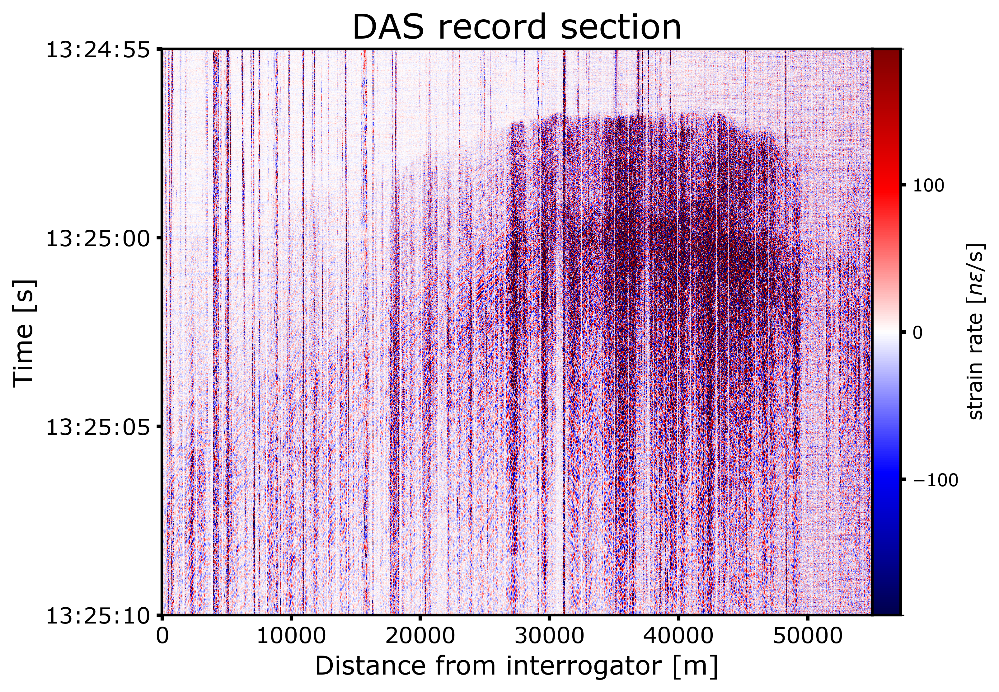

In [3]:
da = xdas.open_dataarray('traces_DAS/SR_DS_CH2_2026-04-12_13-24-54_UTC.nc')
da = xdas.signal.detrend(da,'constant')
da = da.sel(time = slice('2026-04-12 13:24:55', '2026-04-12 13:25:10'))
plot_DAS(da, sat = 20)

353.9852
Converted DAS in 2751 channels
2751 Trace(s) in Stream:

NET.DAS00001.00.HN1 | 2026-04-12T13:24:14.500000Z - 2026-04-12T13:26:14.490000Z | 100.0 Hz, 12000 samples
...
(2749 other traces)
...
NET.DAS02751.00.HN1 | 2026-04-12T13:24:14.500000Z - 2026-04-12T13:26:14.490000Z | 100.0 Hz, 12000 samples

[Use "print(Stream.__str__(extended=True))" to print all Traces]


c:\Users\franc\anaconda3\envs\summer_school\Lib\site-packages\matplotlib\dates.py:449: UserWarning: no explicit representation of timezones available for np.datetime64
  d = d.astype('datetime64[us]')
c:\Users\franc\anaconda3\envs\summer_school\Lib\site-packages\matplotlib\dates.py:449: UserWarning: no explicit representation of timezones available for np.datetime64
  d = d.astype('datetime64[us]')
c:\Users\franc\anaconda3\envs\summer_school\Lib\site-packages\matplotlib\dates.py:449: UserWarning: no explicit representation of timezones available for np.datetime64
  d = d.astype('datetime64[us]')
c:\Users\franc\anaconda3\envs\summer_school\Lib\site-packages\matplotlib\dates.py:449: UserWarning: no explicit representation of timezones available for np.datetime64
  d = d.astype('datetime64[us]')


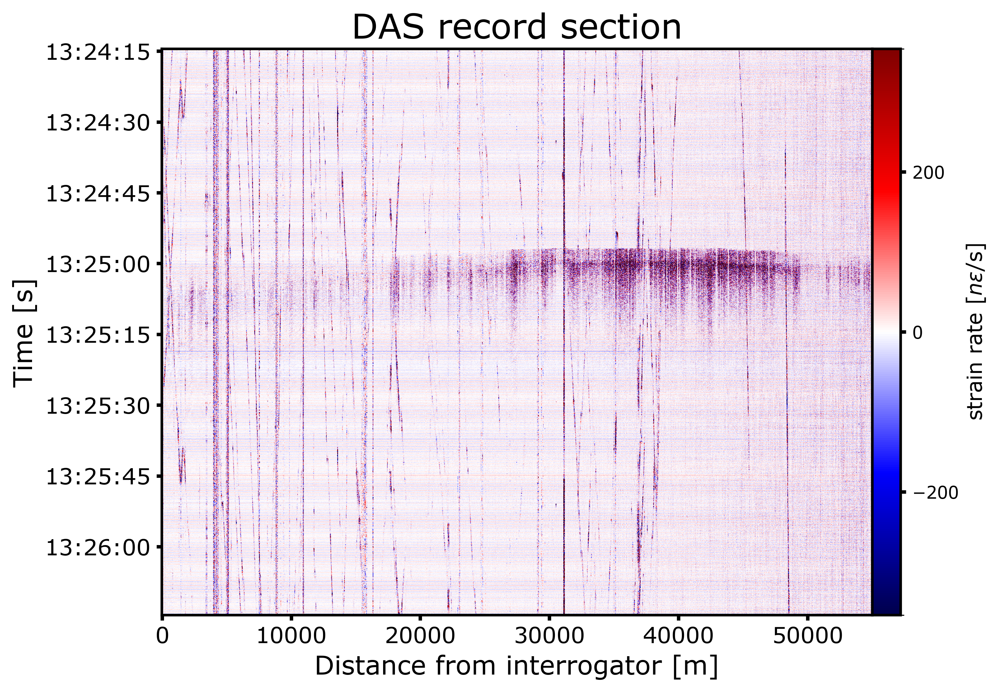

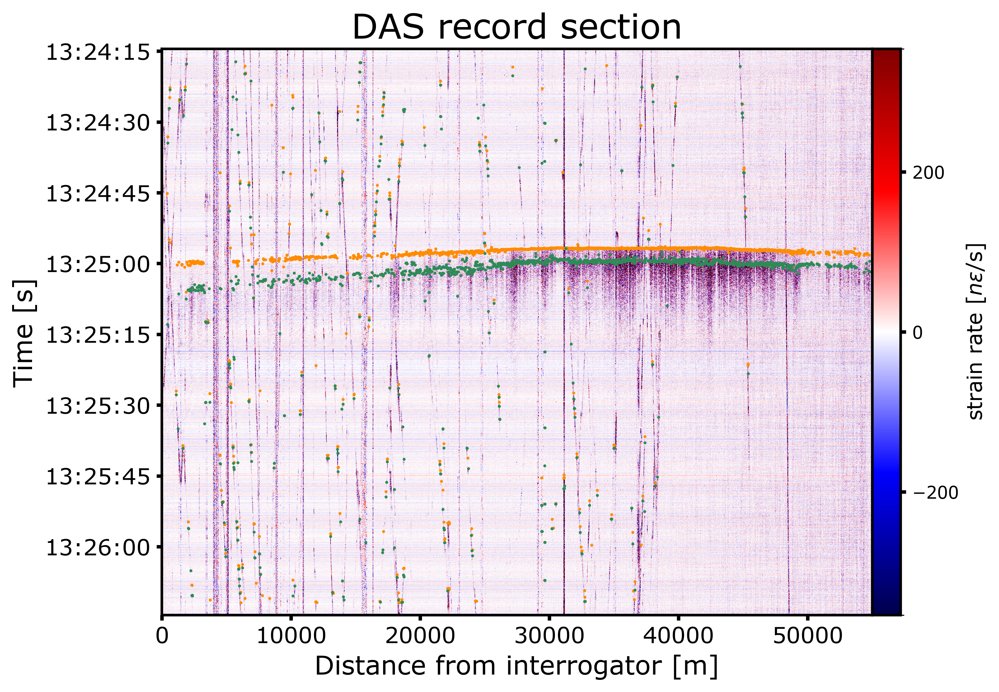

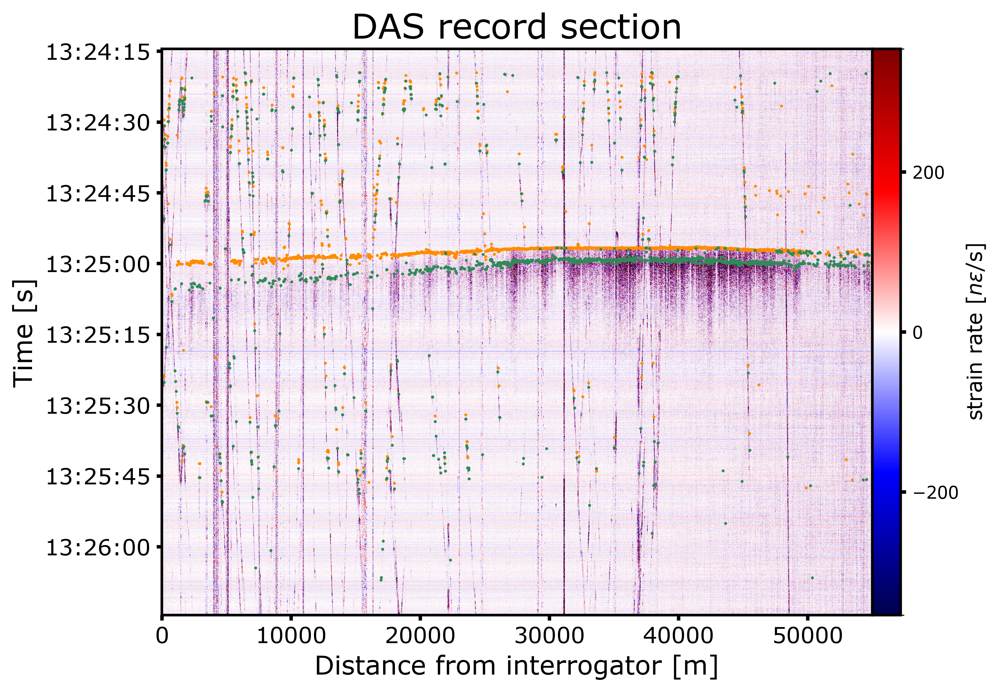

In [7]:
pn_model = sbm.PhaseNet.from_pretrained('original')
pn_model_diting = sbm.PhaseNet.from_pretrained('diting')
pick_folder = 'picks'
write = True
plot = True

#Open DAS data
da = xdas.open_dataarray('traces_DAS/SR_DS_CH2_2026-04-12_13-24-54_UTC.nc')
plot_DAS(da, sat = 20, time_deci = 2)

#Convert to virtual receivers
traces_DAS = da.load().to_stream()
print(f"Converted DAS in {len(traces_DAS)} channels")
print(traces_DAS)

# Annotate with PhaseNet models
models = [pn_model, pn_model_diting]
models_string = ['original', 'diting']
if not os.path.exists(pick_folder):
    os.mkdir(pick_folder)

for model, model_string in zip(models, models_string):
    #write picks
    if write:
        #Apply the model
        picks = model.classify(traces_DAS)
        with open(f"{pick_folder}/event_{model_string}.txt",'w') as fout:
            fout.write('CHANNEL,OFFSET,TIME,PHASE,PROB\n')
            for p in picks.picks:
                #print(p)
                channel = int(p.trace_id.split('.')[1].split('DAS')[-1]) - 1
                offset = da["distance"][int(channel)].values
                time = str(p.peak_time)
                prob = p.peak_value
                phase = p.phase
                fout.write(f"{channel},{offset:.2f},{time},{phase.lower()},{prob:.2f}\n")
    if plot:
        picks = pd.read_csv(f"{pick_folder}/event_{model_string}.txt")
        plot_picks(da, picks, time_deci = 2, space_deci = 1, sat = 20, size = 0.5)

# PHASE ASSOCIATION

Associating 3784 picks with 1 CPUs
.

c:\Users\franc\anaconda3\envs\summer_school\Lib\site-packages\gamma\_base.py:275: ConvergenceWarning: Initialization did not converge.
  warnings.warn(


Associated events with 1720 P and 1019 S picks


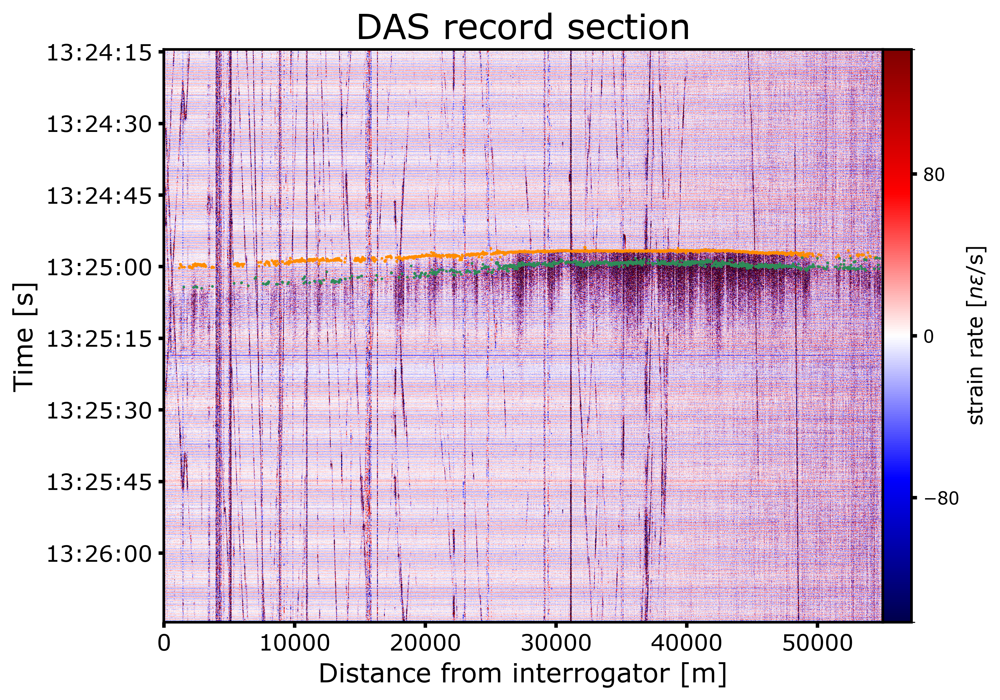

In [10]:

gamma_folder = 'gamma_picks'

associate(da,
          pick_folder, 
          model_string = 'diting',
          gamma_picks = gamma_folder, 
          prob_thresh = 0.2,
          plot = True)

# Visualize automatic picks

        ID  ID_OLD                              TIME  PROB PHASE   OFFSET
1039  1792    1792  2026-04-12 13:24:59.380000+00:00  0.66     s  35840.0
1540  1792    1792  2026-04-12 13:24:56.820000+00:00  0.87     p  35840.0


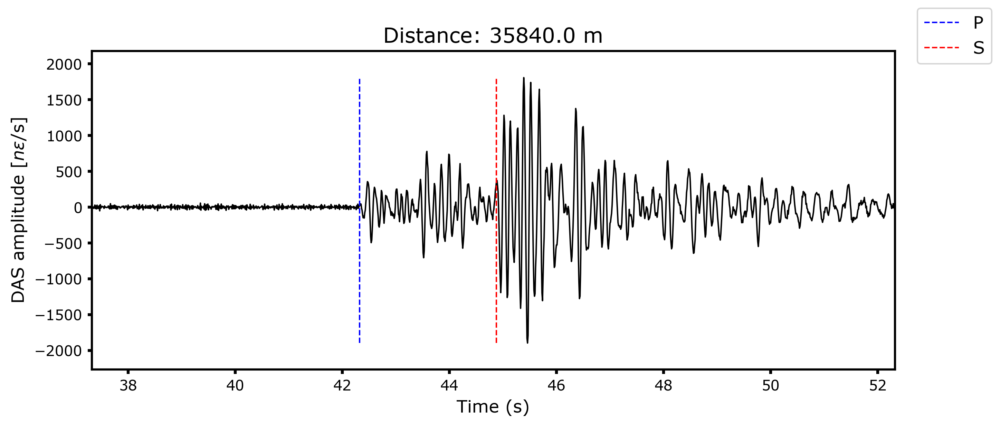

In [11]:
model = 'diting'

picks = pd.read_csv(f"{gamma_folder}/event_{model}.txt")

#Extract channel to plot
idx_to_plot = 1792 #np.random.choice(np.unique(picks["ID"]))
picks_channel = picks[picks["ID"] == idx_to_plot]
print(picks_channel)
phases = ['p', 's']
colors = ['b', 'r']

fig, ax = plt.subplots(1,1, figsize = (10,4))
ax.plot(traces_DAS[idx_to_plot - 1].times(), 
        traces_DAS[idx_to_plot - 1].data,
        color = 'k')
for phase, color in zip(phases,colors):
    if phase in picks_channel["PHASE"].values:
        pick_marker = UTCDateTime(picks_channel["TIME"][picks_channel["PHASE"] == phase].values[0].split('+')[0]) - traces_DAS[idx_to_plot - 1].stats.starttime
        ax.vlines(pick_marker, 
                  min(traces_DAS[idx_to_plot - 1].data), 
                  max(traces_DAS[idx_to_plot - 1].data),
                  color = color,
                  linestyles = '--',
                  label = phase.upper())
edge_left = UTCDateTime(min(picks_channel["TIME"]).split('+')[0]) - traces_DAS[idx_to_plot - 1].stats.starttime
ax.set_xlim(edge_left - 5, edge_left + 10)
ax.set_title(f"Distance: {picks_channel['OFFSET'].values[0]:.1f} m")
ax.set_xlabel('Time (s)')
ax.set_ylabel(r"DAS amplitude [$n\varepsilon$/s]")
fig.legend()




# Application to continuous data

74.76114


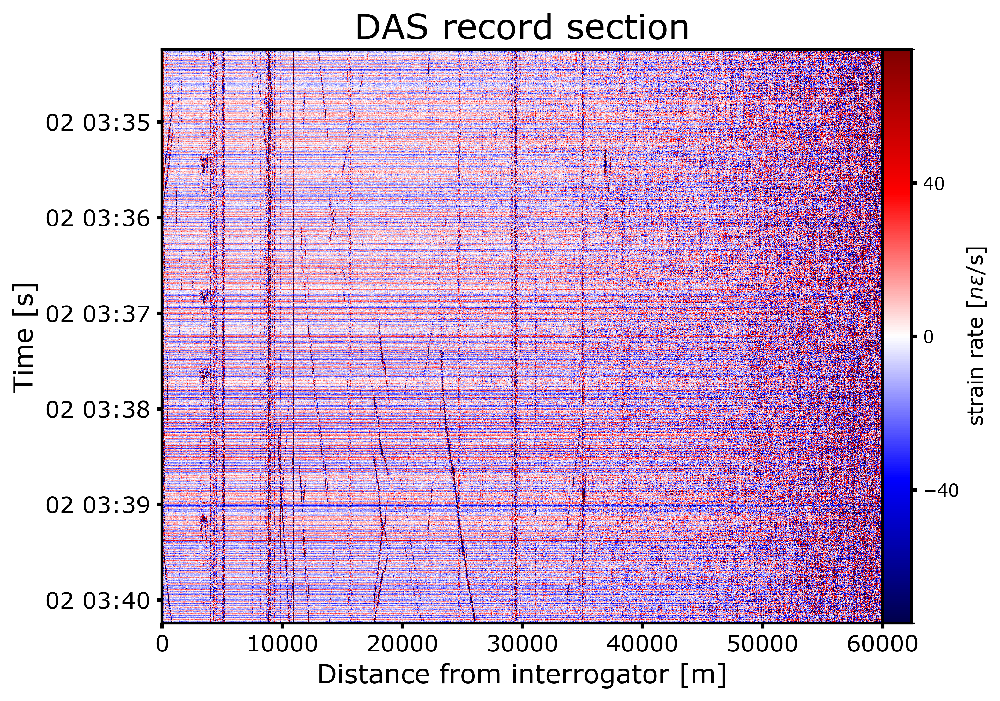

In [18]:
da = xdas.open_mfdataarray('traces_DAS_continuous/*', engine = 'febus')
plot_DAS(da.to_xarray(), sat = 100, time_deci = 10)

Converted DAS in 3001 channels
3001 Trace(s) in Stream:

NET.DAS00001.00.HN1 | 2026-03-02T03:34:14.500000Z - 2026-03-02T03:40:14.490000Z | 100.0 Hz, 36000 samples
...
(2999 other traces)
...
NET.DAS03001.00.HN1 | 2026-03-02T03:34:14.500000Z - 2026-03-02T03:40:14.490000Z | 100.0 Hz, 36000 samples

[Use "print(Stream.__str__(extended=True))" to print all Traces]


c:\Users\franc\anaconda3\envs\summer_school\Lib\site-packages\matplotlib\dates.py:449: UserWarning: no explicit representation of timezones available for np.datetime64
  d = d.astype('datetime64[us]')
c:\Users\franc\anaconda3\envs\summer_school\Lib\site-packages\matplotlib\dates.py:449: UserWarning: no explicit representation of timezones available for np.datetime64
  d = d.astype('datetime64[us]')


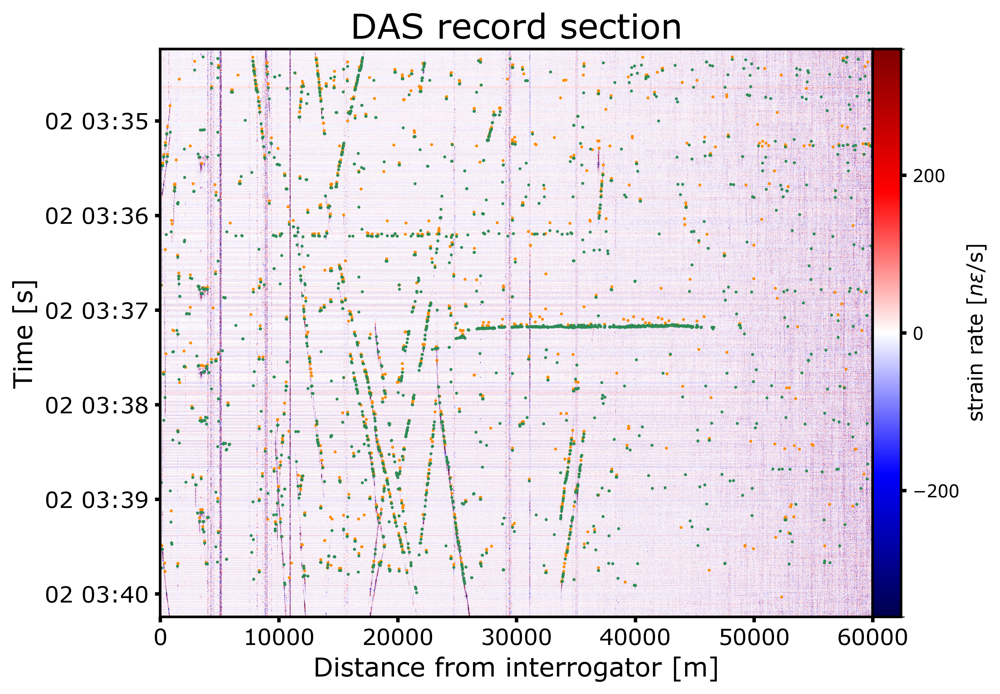

In [20]:
pn_model_diting = sbm.PhaseNet.from_pretrained('diting')

pick_folder = 'picks_continuous'
write = True
plot = True

#Convert to virtual receivers
traces_DAS = da.load().to_stream()
print(f"Converted DAS in {len(traces_DAS)} channels")
print(traces_DAS)

# Annotate with PhaseNet models
models = [pn_model_diting]
models_string = ['diting']
if not os.path.exists(pick_folder):
    os.mkdir(pick_folder)

for model, model_string in zip(models, models_string):
    #write picks
    if write:
        #Apply the model
        picks = model.classify(traces_DAS)
        with open(f"{pick_folder}/event_{model_string}.txt",'w') as fout:
            fout.write('CHANNEL,OFFSET,TIME,PHASE,PROB\n')
            for p in picks.picks:
                #print(p)
                channel = int(p.trace_id.split('.')[1].split('DAS')[-1]) - 1
                offset = da["distance"][int(channel)].values
                time = str(p.peak_time)
                prob = p.peak_value
                phase = p.phase
                fout.write(f"{channel},{offset:.2f},{time},{phase.lower()},{prob:.2f}\n")
    if plot:
        picks = pd.read_csv(f"{pick_folder}/event_{model_string}.txt")
        plot_picks(da.to_xarray(), picks, time_deci = 10, space_deci = 1, sat = 20, size = 0.5)

Associating 3703 picks with 1 CPUs
.

c:\Users\franc\anaconda3\envs\summer_school\Lib\site-packages\gamma\_base.py:275: ConvergenceWarning: Initialization did not converge.
  warnings.warn(


Associated events with 39 P and 533 S picks


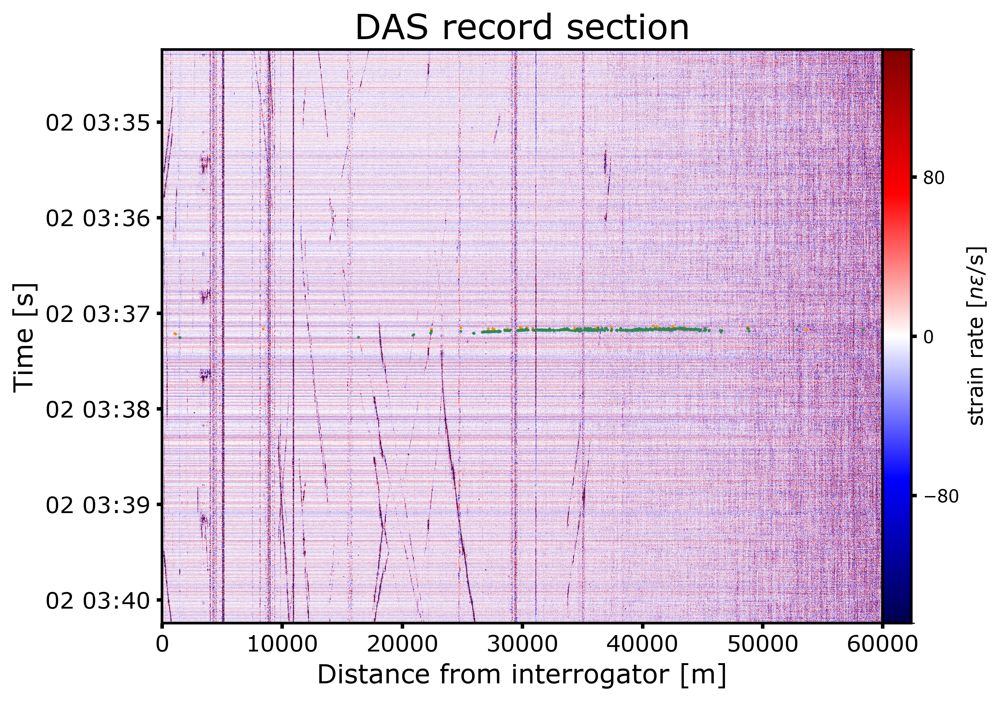

In [22]:
gamma_folder = 'gamma_picks_continuous'

associate(da.to_xarray(),
          pick_folder, 
          model_string = 'diting',
          gamma_picks = gamma_folder, 
          prob_thresh = 0.2,
          plot = True)



120.60562436543736


c:\Users\franc\anaconda3\envs\summer_school\Lib\site-packages\matplotlib\dates.py:449: UserWarning: no explicit representation of timezones available for np.datetime64
  d = d.astype('datetime64[us]')
c:\Users\franc\anaconda3\envs\summer_school\Lib\site-packages\matplotlib\dates.py:449: UserWarning: no explicit representation of timezones available for np.datetime64
  d = d.astype('datetime64[us]')


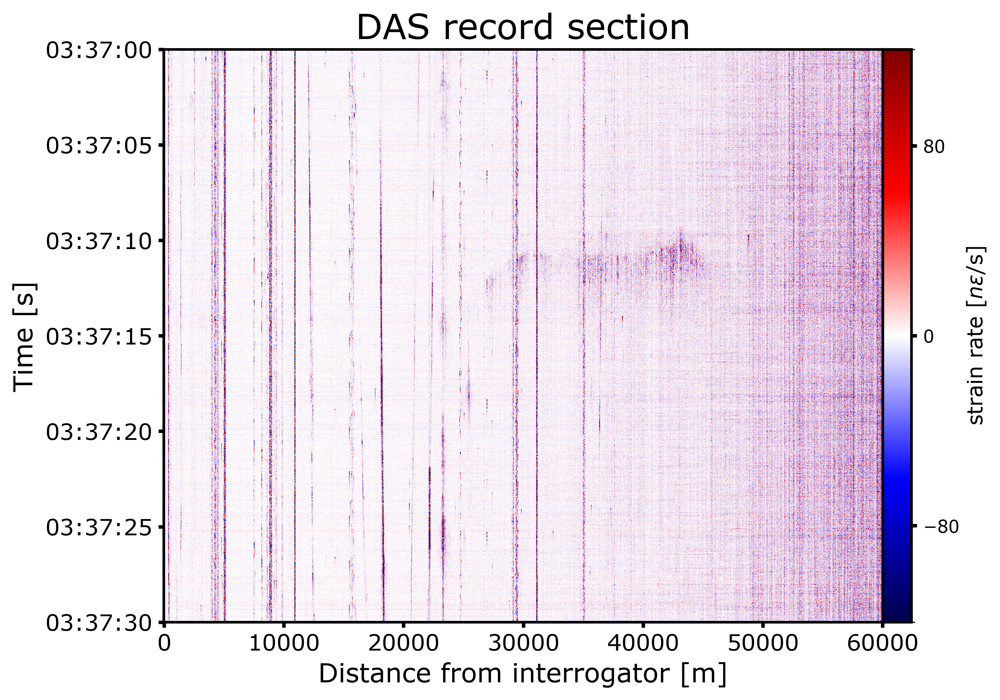

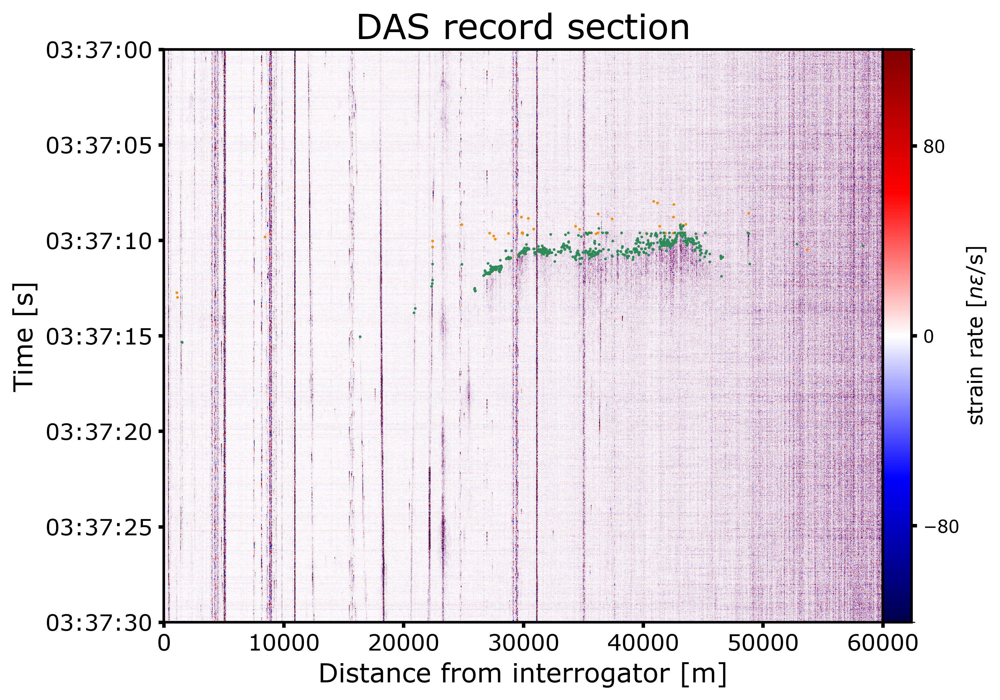

In [23]:
gamma_picks = pd.read_csv(f"{gamma_folder}/event_diting.txt")
da = da.sel(time = slice('2026-03-02 03:37:00', '2026-03-02 03:37:30'))
da = xdas.signal.filter(da, freq = [1,20], btype='bandpass',corners  = 2, dim = 'time')

plot_DAS(da,
    time_deci = 2,
    sat = 20)

plot_picks(da,
           gamma_picks,
           time_deci = 2,
           sat = 20)